# Computer Vision 2026-2027 - NOVA FCT

## Project Stage 1 - Shot boundary detection and recurring scenes

**Authors**:
- 73287, Beatriz Guerreiro, br.guerreiro@campus.fct.pt
- 73986, Maria Francisca Inácio, 

## 1. Introduction

## 2. Part 1 - Frame dissimilarity and hard cuts

In [1]:
import tp1, metrics
import cv2 as cv
import matplotlib.pyplot as plt
import plotting

girls_rot = cv.imread("../girls_closeup_rot.jpg")
girls = cv.imread("../girls_closeup.jpg")
trees = cv.imread("../trees.jpg")

print(tp1.pixel_difference(cv.resize(trees, (256, 256)), girls))
print(tp1.pixel_difference(girls_rot, girls))


156.26565551757812
131.7107391357422


In [2]:
hist1 = tp1.bgr_histogram(girls)
hist2 = tp1.bgr_histogram(trees)

tp1.histogram_distance(hist1, hist2)

np.float64(0.2428488436736854)

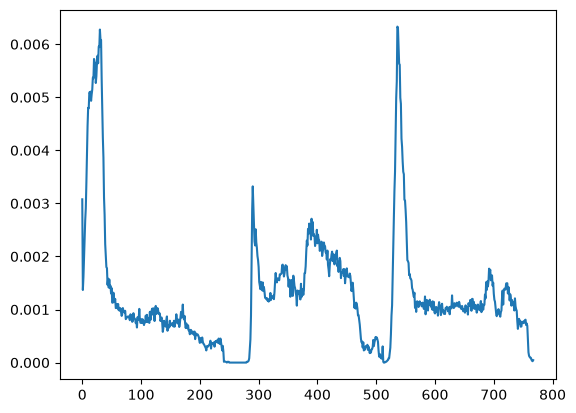

In [3]:

plt.plot(tp1.bgr_histogram(girls))
plt.show()

In [14]:
import json

video = cv.VideoCapture("../input/dev_01.mp4")
with open("../input/dev_01.json", "r") as file:
  data = json.load(file)

fps = data["fps"]
total_frames = data["num_frames"]

d_pixel, d_hist, d_ecr = [], [], []

_, prev_frame = video.read()
for i in range(total_frames-1):
  ret, frame = video.read()

  if not ret:
    break

  hist1 = tp1.bgr_histogram(prev_frame)
  hist2 = tp1.bgr_histogram(frame)

  pixel_dif = tp1.pixel_difference(prev_frame, frame)
  hist_dif = tp1.histogram_distance(hist1, hist2)
  ecr = tp1.edge_change_ration(prev_frame, frame)

  d_pixel.append(pixel_dif)
  d_hist.append(hist_dif)
  d_ecr.append(ecr)

  prev_frame = frame

video.release()

signals = {"histogram": d_hist, "pixel": d_pixel, "ecr":d_ecr}


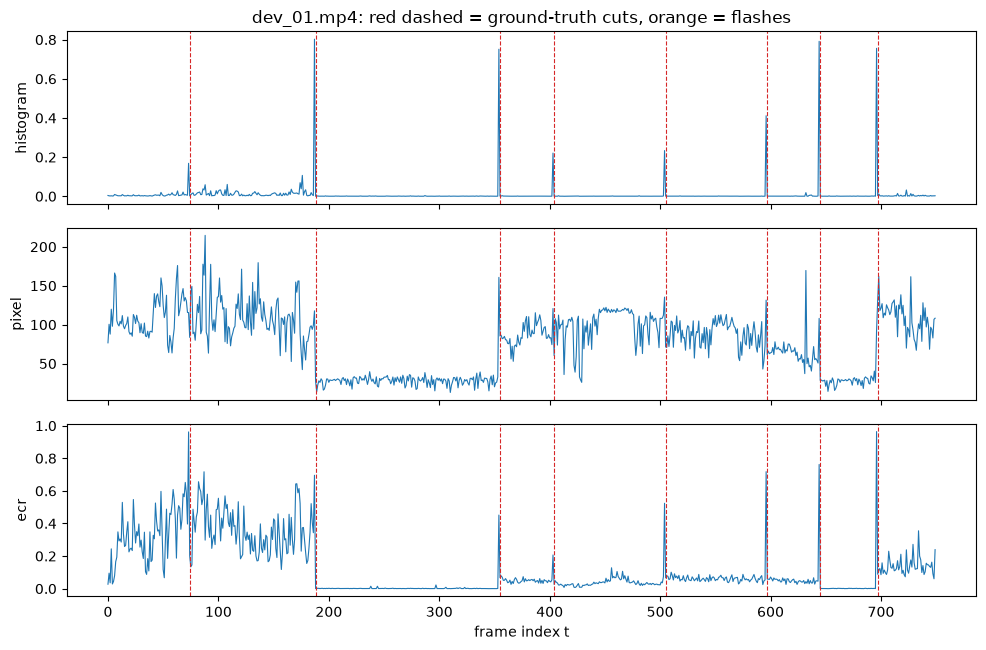

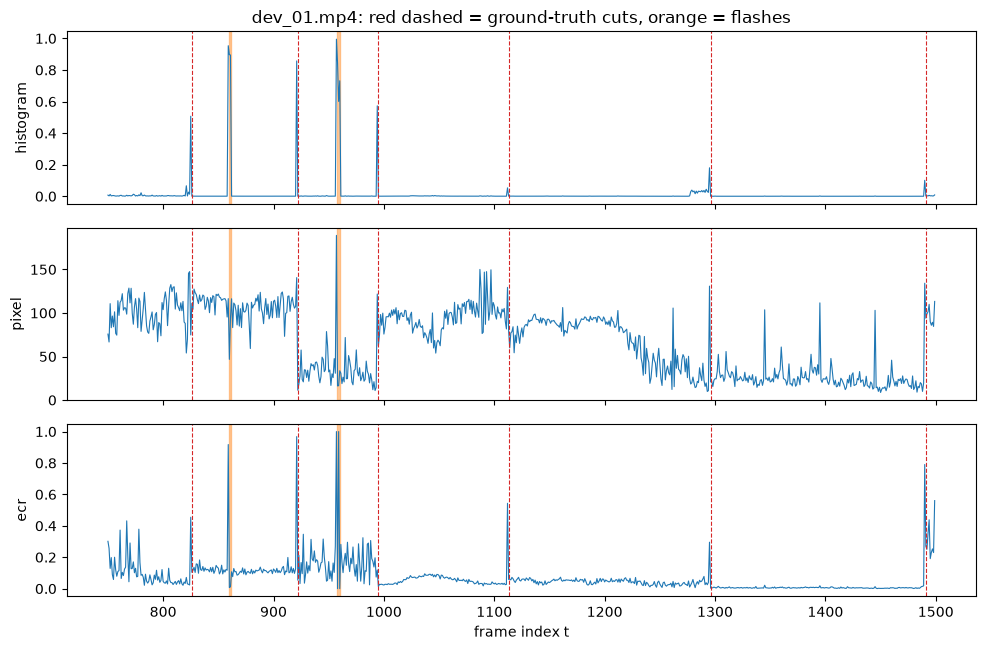

In [16]:
segs = 30

# plot dos primeiros 30s
p1 = plotting.plot_signals(signals=signals, gt=data, start=0, end=fps*segs)

#plot dos 30 aos 60s
p2 = plotting.plot_signals(signals=signals, gt=data, start=fps*segs, end=fps*segs*2)

In [8]:
import metrics

transitions = [ #exemplo de quais cuts detetamos
  {"type": "cut", "start": 74, "end": 74},
  {"type": "cut", "start": 100, "end": 101},
    {"type": "cut", "start": 188, "end": 188}]

# Exemplo para um vídeo ou somando os dev videos:
pred_cuts = [t["start"] for t in transitions]
gt_cuts = [t["start"] for t in data["transitions"]] 

tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)
precision, recall, f1 = metrics.precision_recall_f1(tp, fp, fn)

print("true positives:", tp)
print("false positives:", fp)
print("FN?:", fn)

print("precision:", precision)
print("recall:", recall)
print("f1:", f1)

true positives: 2
false positives: 1
FN?: 34
precision: 0.6666666666666666
recall: 0.05555555555555555
f1: 0.10256410256410256


In [23]:
with open("../input/dev_02.json", "r") as file:
  data2 = json.load(file)

cuts = data # como ainda nao temos os cuts mete se o data so para testar
#o objetivo é ir ao tp1.py preencher o process_video que retorna (transitions, scenes)  e depois usar as transitions acho eu

# avalia os 2 videos
dict_dev1 = metrics.evaluate_video(data, cuts) 
dict_dev2 = metrics.evaluate_video(data2, cuts)


sum = metrics.sum_counts([dict_dev1, dict_dev2])

metrics.print_table([("TEST", sum)])

video       cut-P  cut-R  cut-F1  flash-FA  scene-P  scene-R  scene-F1
TEST        0.514  0.529   0.521      0/12    0.000    0.000     0.000


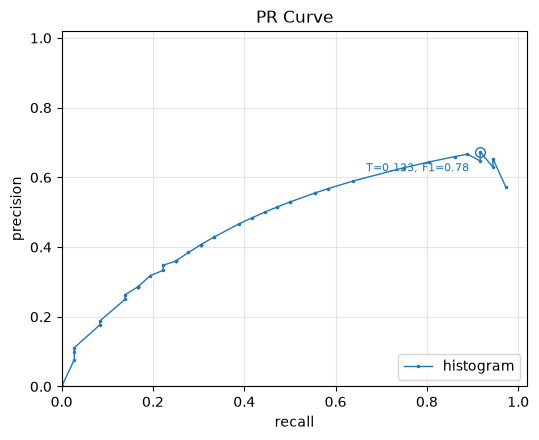

In [17]:
import numpy as np
import metrics
import plotting

gt_cuts = [t["start"] for t in data["transitions"]]

curves = {"histogram": []}

for T in np.linspace(0.05, 0.95, 50):

    pred_cuts = [i + 1 for i, val in enumerate(d_hist) if val > T]
    
    tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)
    p, r, f1 = metrics.precision_recall_f1(tp, fp, fn)
    
    curves["histogram"].append((T, p, r))

fig = plotting.plot_pr_curve(curves, title="PR Curve")

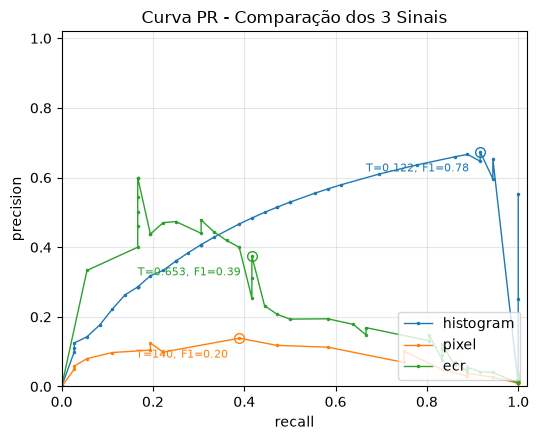

In [22]:
import numpy as np
import metrics
import plotting

def add_signal_to_curve(curves_dict, signal_name, signal_values, gt_cuts, t_min=0.05, t_max=0.95, num_steps=50):
  curves_dict[signal_name] = []
  for T in np.linspace(t_min, t_max, num_steps):
        
    pred_cuts = [i + 1 for i, val in enumerate(signal_values) if val > T]

    tp, fp, fn = metrics.match_cuts(gt_cuts, pred_cuts)
    p, r, f1 = metrics.precision_recall_f1(tp, fp, fn)
    
    curves_dict[signal_name].append((T, p, r))
        
  return curves_dict


curves = {}

gt_cuts = [t["start"] for t in data["transitions"]]

add_signal_to_curve(curves, "histogram", d_hist, gt_cuts, t_min=0.0, t_max=1.0, num_steps=50)
add_signal_to_curve(curves, "pixel", d_pixel, gt_cuts, t_min=0.0, t_max=max(d_pixel), num_steps=50)
add_signal_to_curve(curves, "ecr", d_ecr, gt_cuts, t_min=0.0, t_max=1.0, num_steps=50)


fig = plotting.plot_pr_curve(curves, title="Curva PR - Comparação dos 3 Sinais", path="../output/pr_curve_all_signals.png")

## 3. Part 2 - Gradual transitions and false alarms

## 4. Part 3 - Recurring scenes

## 5. Results (development and test)

## 6. Analysis and failure cases

## 7. Conclusion and self-evaluation

## 8. Extras

## 9. Use of AI tools